DATASET INFORMATION
Original records: 29531
Records after cleaning: 16626
Number of cities: 25
Number of features: 4

DATASET SAMPLE
           City       Date  PM2.5    PM10     NO    NO2    NOx  NH3     CO  \
1595  Ahmedabad 2019-05-15  37.55  122.41  15.08  85.12  58.72  NaN  15.08   
1596  Ahmedabad 2019-05-16  33.97  116.32  14.67  79.71  55.61  NaN  14.67   
1597  Ahmedabad 2019-05-17  35.48  130.07  18.02  77.61  58.41  NaN  18.02   
1598  Ahmedabad 2019-05-18  34.11  138.31  13.27  75.23  51.83  NaN  13.27   
1599  Ahmedabad 2019-05-19  33.69  111.73  34.56  68.90  69.77  NaN  34.56   

         SO2     O3  Benzene  Toluene  Xylene    AQI AQI_Bucket  Month  Year  
1595  163.01  48.23    16.44    85.54   14.19  281.0       Poor      5  2019  
1596   91.26  51.86    15.55    83.89   13.15  330.0  Very Poor      5  2019  
1597   98.35  38.99    15.88    83.83   13.34  356.0  Very Poor      5  2019  
1598   88.66  42.22    15.93    82.73   13.44  359.0  Very Poor      5  2019  
159

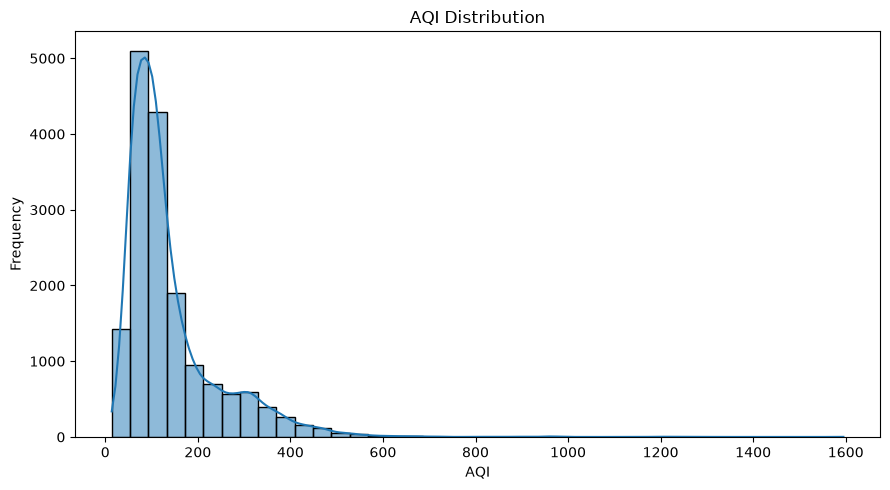

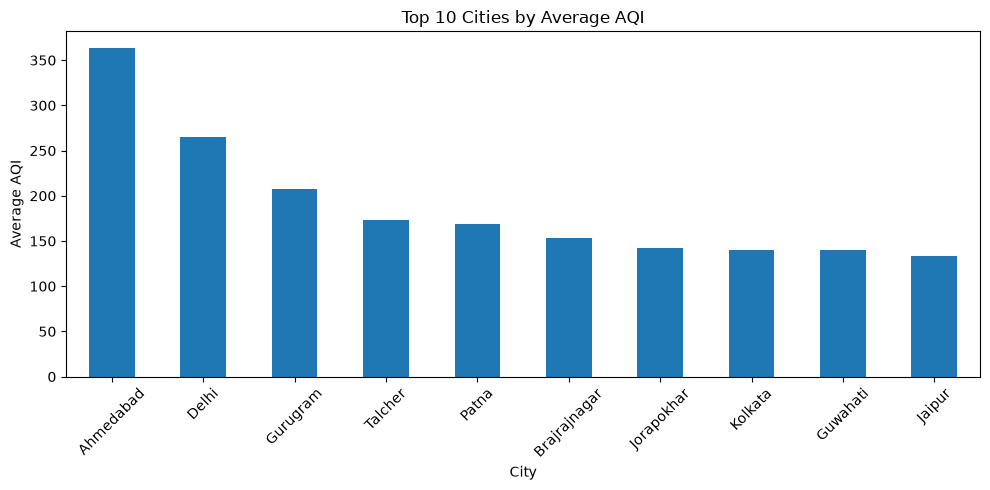

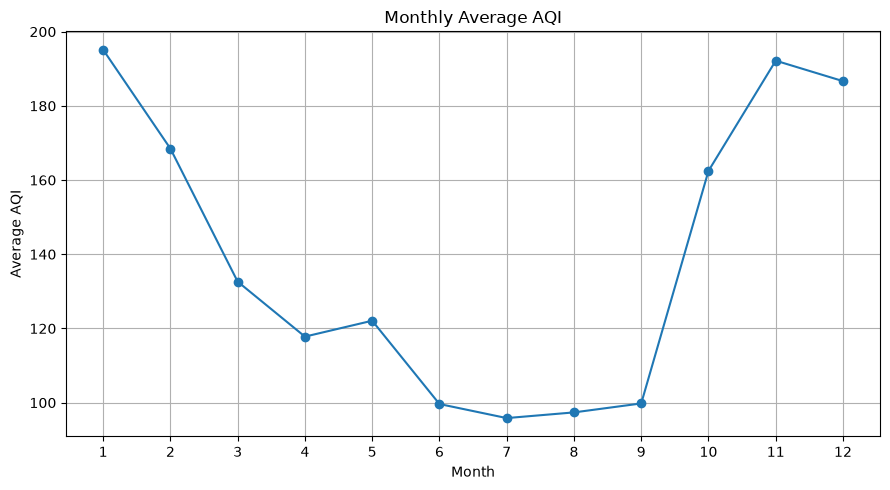

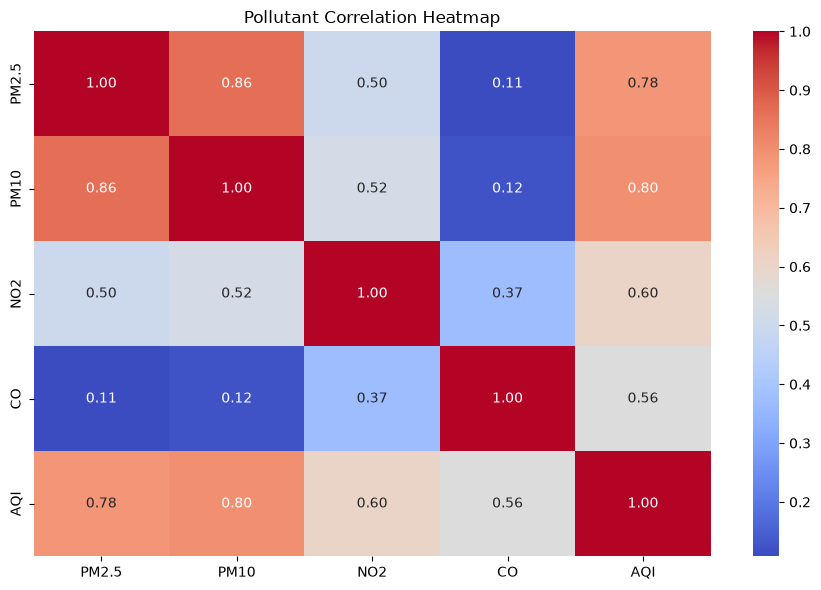


REGRESSION MODELS

1. SIMPLE LINEAR REGRESSION
Input feature: PM2.5
R2 Score: 0.631
MAE: 33.64
MSE: 3937.24
RMSE: 62.75

2. POLYNOMIAL REGRESSION
Input feature: PM10
Polynomial degree: 2
R2 Score: 0.6612
MAE: 33.07
MSE: 3614.49
RMSE: 60.12

3. MULTIPLE LINEAR REGRESSION
Input features: ['PM2.5', 'PM10', 'NO2', 'CO']
R2 Score: 0.8835
MAE: 22.38
MSE: 1242.91
RMSE: 35.25

REGRESSION MODEL COMPARISON
                          Model  R2 Score     MAE    RMSE
0      Simple Linear Regression     0.631  33.645  62.747
1  Polynomial Regression (PM10)     0.661  33.071  60.121
2    Multiple Linear Regression     0.883  22.380  35.255


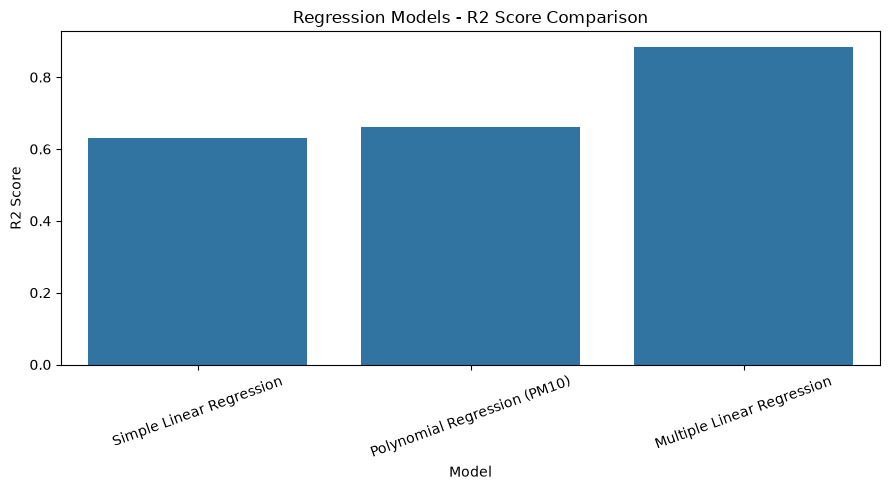

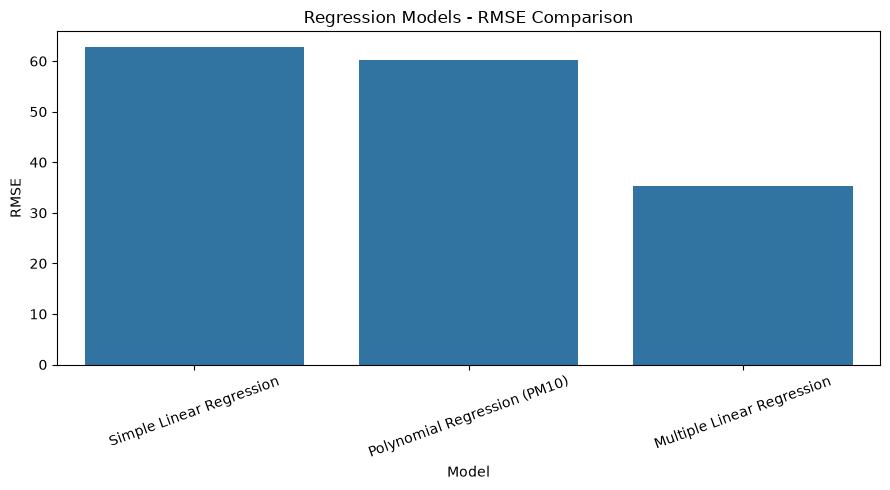

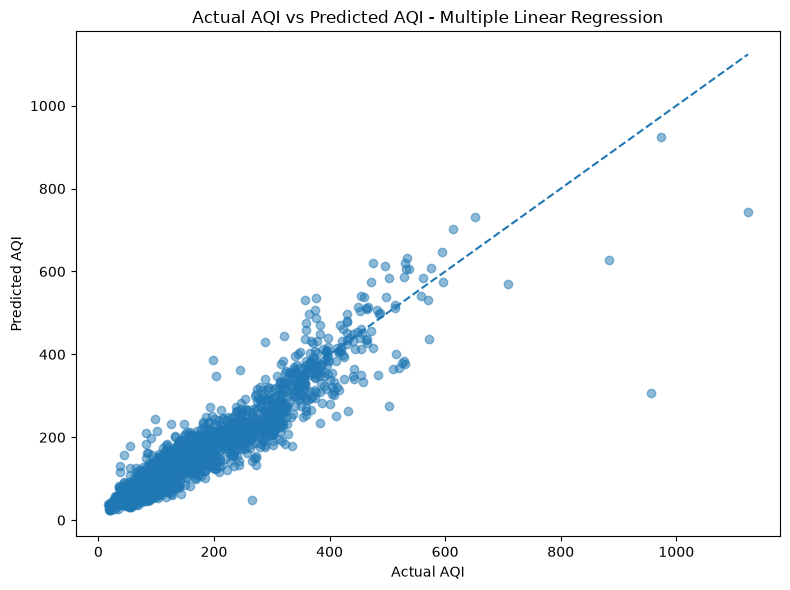


AQI PREDICTION RESULTS
    Actual AQI  Simple Linear Prediction  Polynomial PM10 Prediction  \
0        142.0                    128.62                      137.79   
1         66.0                    111.85                       85.79   
2         68.0                     88.59                       70.01   
3         69.0                    110.63                      130.02   
4         86.0                    120.68                       94.23   
5         79.0                     87.12                       82.41   
6         74.0                    106.36                       80.74   
7         99.0                    111.95                      109.13   
8         36.0                     71.76                       53.36   
9        105.0                    134.50                      116.17   
10        95.0                    110.36                      122.49   
11       109.0                    149.40                      108.79   
12        81.0                    112.48

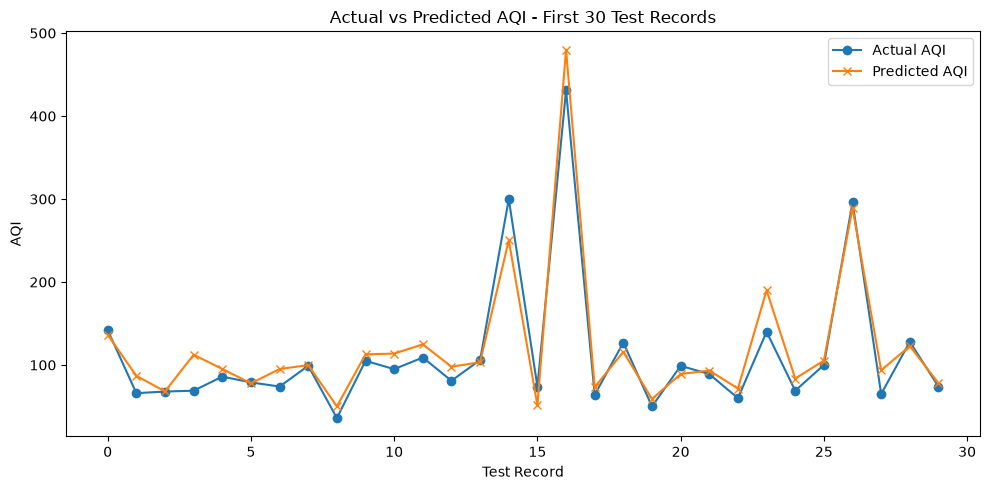

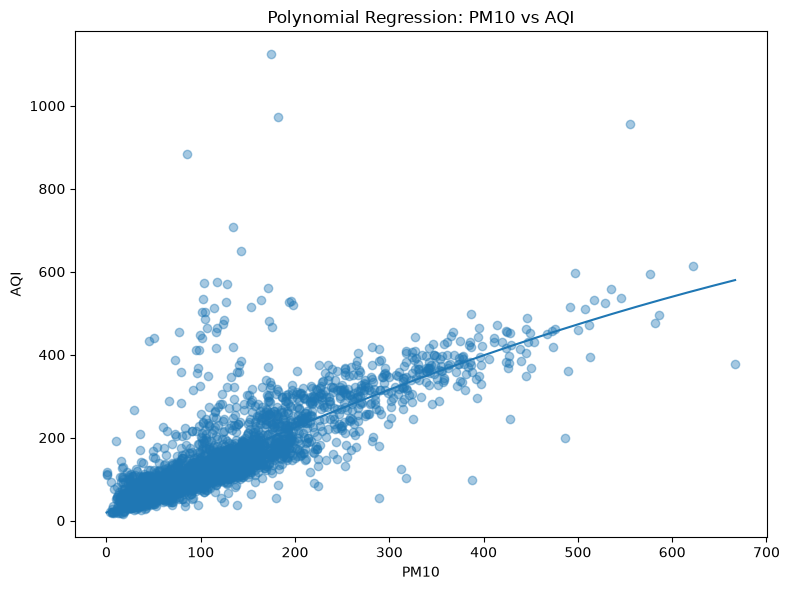


CLASSIFICATION MODELS

4. LOGISTIC REGRESSION
Accuracy: 0.7712
Precision: 0.7663
Recall: 0.7712
F1 Score: 0.7638
Log Loss: 0.5817
Multiclass AUC: 0.9341

5. DECISION TREE CLASSIFIER
Accuracy: 0.7796
Precision: 0.7751
Recall: 0.7796
F1 Score: 0.7758
Log Loss: 0.6756
Multiclass AUC: 0.9209

CLASSIFICATION MODEL COMPARISON
                 Model  Accuracy  Precision  Recall  F1 Score  Log Loss  \
0  Logistic Regression    0.7712     0.7663  0.7712    0.7638    0.5817   
1        Decision Tree    0.7796     0.7751  0.7796    0.7758    0.6756   

      AUC  
0  0.9341  
1  0.9209  


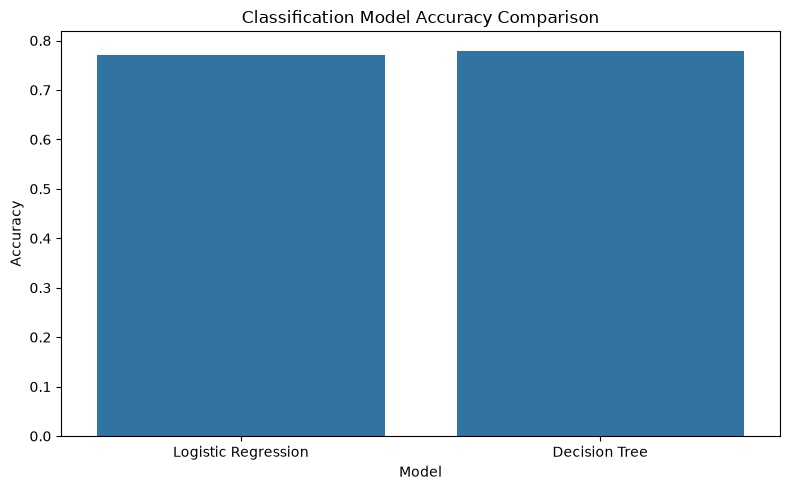

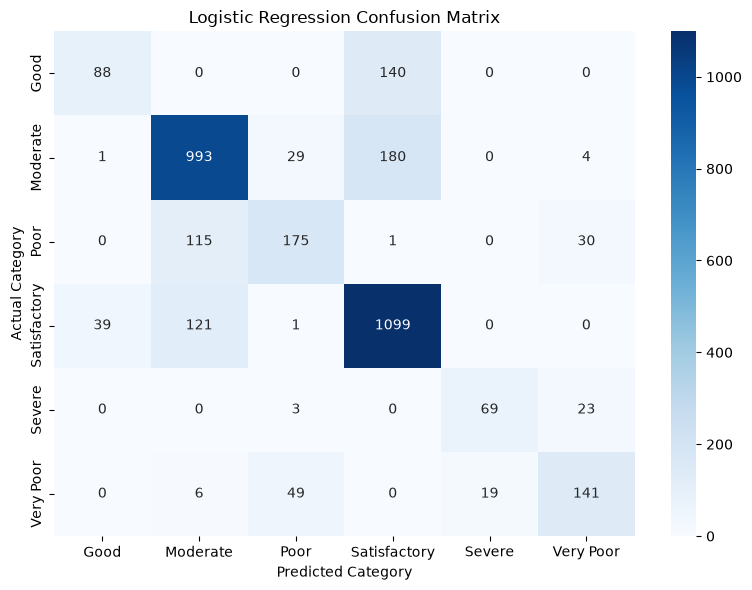

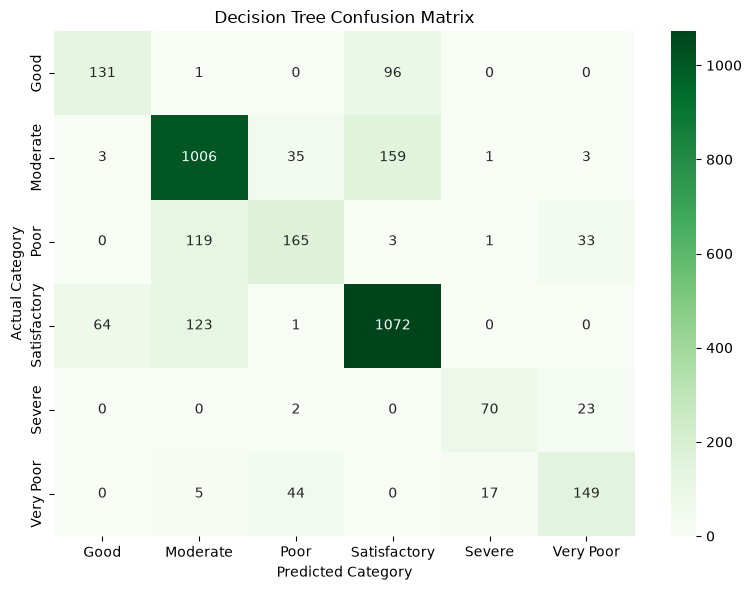

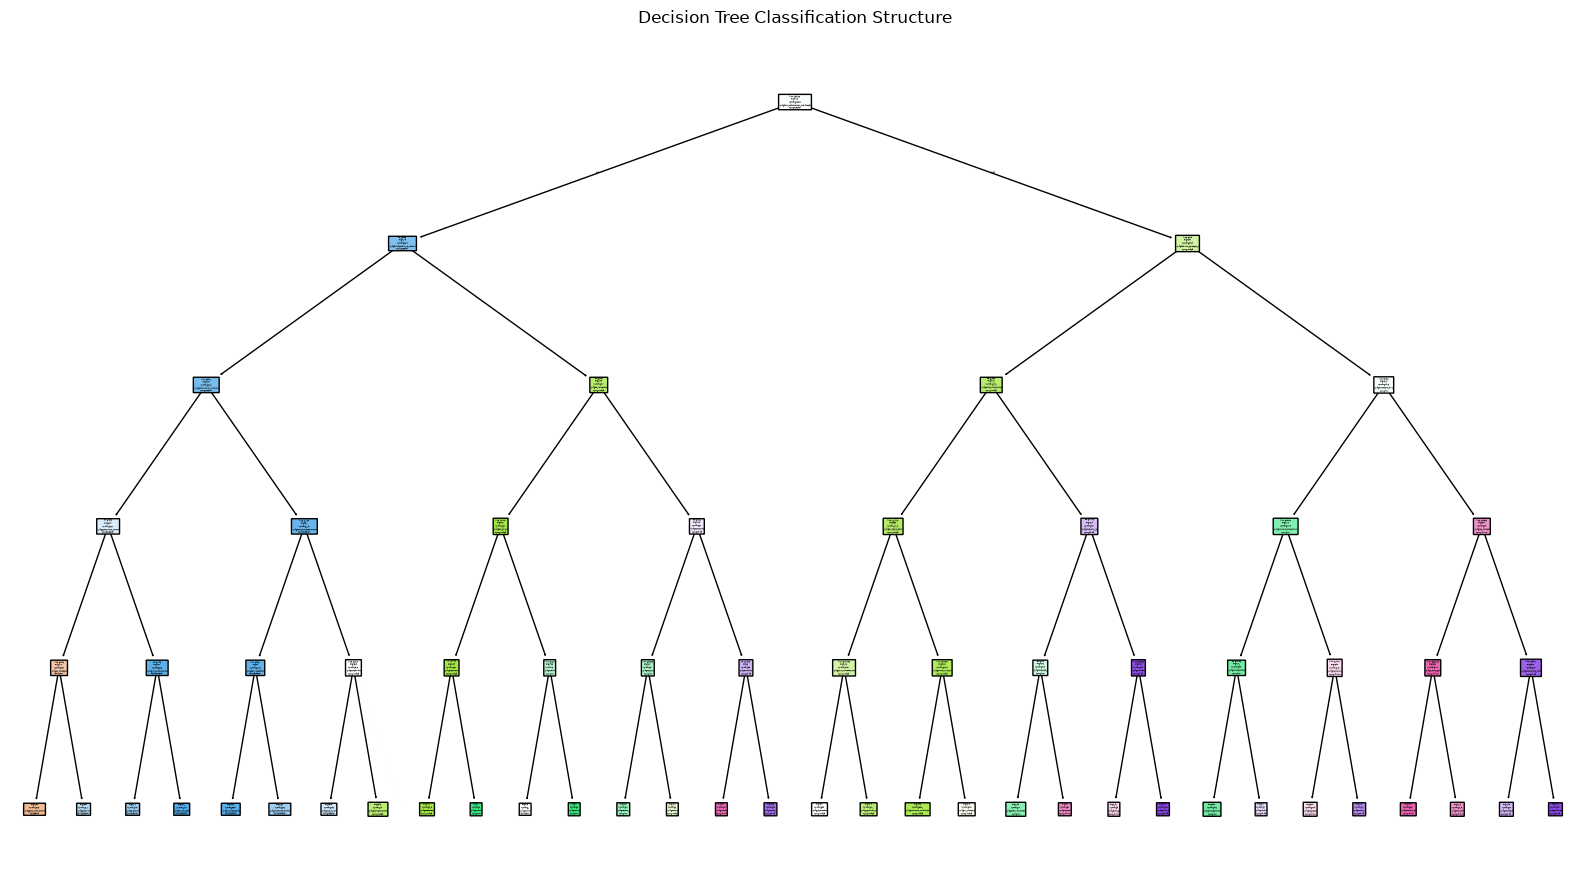


AQI CATEGORY PREDICTION RESULTS
   Actual Category Logistic Regression Prediction Decision Tree Prediction
0             Poor                           Poor                     Poor
1             Good                   Satisfactory             Satisfactory
2         Moderate                       Moderate                 Moderate
3             Poor                           Poor                     Poor
4         Moderate                       Moderate                 Moderate
5        Very Poor                      Very Poor                Very Poor
6             Poor                           Poor                     Poor
7         Moderate                   Satisfactory             Satisfactory
8        Very Poor                      Very Poor                Very Poor
9             Poor                      Very Poor                     Poor
10    Satisfactory                   Satisfactory             Satisfactory
11          Severe                         Severe                  

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv("city_day.csv")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

features = ["PM2.5", "PM10", "NO2", "CO"]

df[features + ["AQI"]] = df[features + ["AQI"]].apply(
    pd.to_numeric, errors="coerce"
)

df = df.drop_duplicates()

data = df.dropna(
    subset=["Date", "City", "AQI", "AQI_Bucket"] + features
).copy()

data["Month"] = data["Date"].dt.month
data["Year"] = data["Date"].dt.year

print("DATASET INFORMATION")
print("Original records:", len(df))
print("Records after cleaning:", len(data))
print("Number of cities:", data["City"].nunique())
print("Number of features:", len(features))

print("\nDATASET SAMPLE")
print(data.head())

print("\nDATASET STATISTICS")
print(data[features + ["AQI"]].describe())

plt.figure(figsize=(9, 5))
sns.histplot(data["AQI"], bins=40, kde=True)
plt.title("AQI Distribution")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
data.groupby("City")["AQI"].mean().sort_values(
    ascending=False
).head(10).plot(kind="bar")
plt.title("Top 10 Cities by Average AQI")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
data.groupby("Month")["AQI"].mean().plot(marker="o")
plt.title("Monthly Average AQI")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))
plt.grid()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(
    data[features + ["AQI"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Pollutant Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\n" + "=" * 55)
print("REGRESSION MODELS")
print("=" * 55)

X = data[features]
y = data["AQI"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

X_simple_train = X_train[["PM2.5"]]
X_simple_test = X_test[["PM2.5"]]

simple_model = LinearRegression()
simple_model.fit(X_simple_train, y_train)

simple_predictions = simple_model.predict(X_simple_test)

simple_r2 = r2_score(y_test, simple_predictions)
simple_mae = mean_absolute_error(y_test, simple_predictions)
simple_mse = mean_squared_error(y_test, simple_predictions)
simple_rmse = np.sqrt(simple_mse)

print("\n1. SIMPLE LINEAR REGRESSION")
print("Input feature: PM2.5")
print("R2 Score:", round(simple_r2, 4))
print("MAE:", round(simple_mae, 2))
print("MSE:", round(simple_mse, 2))
print("RMSE:", round(simple_rmse, 2))

X_poly_train = X_train[["PM10"]]
X_poly_test = X_test[["PM10"]]

polynomial = PolynomialFeatures(degree=2)

X_poly_train_transformed = polynomial.fit_transform(X_poly_train)
X_poly_test_transformed = polynomial.transform(X_poly_test)

polynomial_model = LinearRegression()
polynomial_model.fit(X_poly_train_transformed, y_train)

polynomial_predictions = polynomial_model.predict(
    X_poly_test_transformed
)

polynomial_r2 = r2_score(y_test, polynomial_predictions)
polynomial_mae = mean_absolute_error(y_test, polynomial_predictions)
polynomial_mse = mean_squared_error(y_test, polynomial_predictions)
polynomial_rmse = np.sqrt(polynomial_mse)

print("\n2. POLYNOMIAL REGRESSION")
print("Input feature: PM10")
print("Polynomial degree: 2")
print("R2 Score:", round(polynomial_r2, 4))
print("MAE:", round(polynomial_mae, 2))
print("MSE:", round(polynomial_mse, 2))
print("RMSE:", round(polynomial_rmse, 2))

multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_predictions = multiple_model.predict(X_test)

multiple_r2 = r2_score(y_test, multiple_predictions)
multiple_mae = mean_absolute_error(y_test, multiple_predictions)
multiple_mse = mean_squared_error(y_test, multiple_predictions)
multiple_rmse = np.sqrt(multiple_mse)

print("\n3. MULTIPLE LINEAR REGRESSION")
print("Input features:", features)
print("R2 Score:", round(multiple_r2, 4))
print("MAE:", round(multiple_mae, 2))
print("MSE:", round(multiple_mse, 2))
print("RMSE:", round(multiple_rmse, 2))

regression_results = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Polynomial Regression (PM10)",
        "Multiple Linear Regression"
    ],
    "R2 Score": [
        simple_r2,
        polynomial_r2,
        multiple_r2
    ],
    "MAE": [
        simple_mae,
        polynomial_mae,
        multiple_mae
    ],
    "RMSE": [
        simple_rmse,
        polynomial_rmse,
        multiple_rmse
    ]
})

print("\nREGRESSION MODEL COMPARISON")
print(regression_results.round(3))

plt.figure(figsize=(9, 5))
sns.barplot(data=regression_results, x="Model", y="R2 Score")
plt.title("Regression Models - R2 Score Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.barplot(data=regression_results, x="Model", y="RMSE")
plt.title("Regression Models - RMSE Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(y_test, multiple_predictions, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.title("Actual AQI vs Predicted AQI - Multiple Linear Regression")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.tight_layout()
plt.show()

prediction_results = pd.DataFrame({
    "Actual AQI": y_test.iloc[:15].values,
    "Simple Linear Prediction": simple_predictions[:15],
    "Polynomial PM10 Prediction": polynomial_predictions[:15],
    "Multiple Linear Prediction": multiple_predictions[:15]
})

print("\nAQI PREDICTION RESULTS")
print(prediction_results.round(2))

plt.figure(figsize=(10, 5))
plt.plot(y_test.iloc[:30].values, marker="o", label="Actual AQI")
plt.plot(multiple_predictions[:30], marker="x", label="Predicted AQI")
plt.title("Actual vs Predicted AQI - First 30 Test Records")
plt.xlabel("Test Record")
plt.ylabel("AQI")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(X_poly_test["PM10"], y_test, alpha=0.4)
pm10_range = np.linspace(
    X_poly_test["PM10"].min(),
    X_poly_test["PM10"].max(),
    200
)
pm10_curve = polynomial_model.predict(
    polynomial.transform(pd.DataFrame({"PM10": pm10_range}))
)
plt.plot(pm10_range, pm10_curve)
plt.title("Polynomial Regression: PM10 vs AQI")
plt.xlabel("PM10")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()

print("\n" + "=" * 55)
print("CLASSIFICATION MODELS")
print("=" * 55)

X_class = data[features]
y_class = data["AQI_Bucket"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

scaler = StandardScaler()

Xc_train_scaled = scaler.fit_transform(Xc_train)
Xc_test_scaled = scaler.transform(Xc_test)

logistic_model = LogisticRegression(
    max_iter=10000,
    solver="lbfgs",
    C=1.0,
    tol=0.0001
)

logistic_model.fit(Xc_train_scaled, yc_train)

logistic_predictions = logistic_model.predict(Xc_test_scaled)
logistic_probabilities = logistic_model.predict_proba(Xc_test_scaled)

logistic_accuracy = accuracy_score(yc_test, logistic_predictions)

logistic_precision = precision_score(
    yc_test, logistic_predictions,
    average="weighted", zero_division=0
)

logistic_recall = recall_score(
    yc_test, logistic_predictions,
    average="weighted", zero_division=0
)

logistic_f1 = f1_score(
    yc_test, logistic_predictions,
    average="weighted", zero_division=0
)

logistic_logloss = log_loss(
    yc_test,
    logistic_probabilities,
    labels=logistic_model.classes_
)

logistic_auc = roc_auc_score(
    yc_test,
    logistic_probabilities,
    multi_class="ovr",
    average="weighted",
    labels=logistic_model.classes_
)

print("\n4. LOGISTIC REGRESSION")
print("Accuracy:", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall:", round(logistic_recall, 4))
print("F1 Score:", round(logistic_f1, 4))
print("Log Loss:", round(logistic_logloss, 4))
print("Multiclass AUC:", round(logistic_auc, 4))

decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

decision_tree_model.fit(Xc_train, yc_train)

tree_predictions = decision_tree_model.predict(Xc_test)
tree_probabilities = decision_tree_model.predict_proba(Xc_test)

tree_accuracy = accuracy_score(yc_test, tree_predictions)

tree_precision = precision_score(
    yc_test, tree_predictions,
    average="weighted", zero_division=0
)

tree_recall = recall_score(
    yc_test, tree_predictions,
    average="weighted", zero_division=0
)

tree_f1 = f1_score(
    yc_test, tree_predictions,
    average="weighted", zero_division=0
)

tree_logloss = log_loss(
    yc_test,
    tree_probabilities,
    labels=decision_tree_model.classes_
)

tree_auc = roc_auc_score(
    yc_test,
    tree_probabilities,
    multi_class="ovr",
    average="weighted",
    labels=decision_tree_model.classes_
)

print("\n5. DECISION TREE CLASSIFIER")
print("Accuracy:", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall:", round(tree_recall, 4))
print("F1 Score:", round(tree_f1, 4))
print("Log Loss:", round(tree_logloss, 4))
print("Multiclass AUC:", round(tree_auc, 4))

classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy
    ],
    "Precision": [
        logistic_precision,
        tree_precision
    ],
    "Recall": [
        logistic_recall,
        tree_recall
    ],
    "F1 Score": [
        logistic_f1,
        tree_f1
    ],
    "Log Loss": [
        logistic_logloss,
        tree_logloss
    ],
    "AUC": [
        logistic_auc,
        tree_auc
    ]
})

print("\nCLASSIFICATION MODEL COMPARISON")
print(classification_results.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=classification_results,
    x="Model",
    y="Accuracy"
)
plt.title("Classification Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion_matrix(yc_test, logistic_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logistic_model.classes_,
    yticklabels=logistic_model.classes_
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion_matrix(yc_test, tree_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=decision_tree_model.classes_,
    yticklabels=decision_tree_model.classes_
)
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

plt.figure(figsize=(16, 9))
plot_tree(
    decision_tree_model,
    feature_names=features,
    class_names=decision_tree_model.classes_,
    filled=True,
    rounded=True
)
plt.title("Decision Tree Classification Structure")
plt.tight_layout()
plt.show()

classification_predictions = pd.DataFrame({
    "Actual Category": yc_test.iloc[:20].values,
    "Logistic Regression Prediction": logistic_predictions[:20],
    "Decision Tree Prediction": tree_predictions[:20]
})

print("\nAQI CATEGORY PREDICTION RESULTS")
print(classification_predictions)

logistic_confidence = logistic_probabilities.max(axis=1)
tree_confidence = tree_probabilities.max(axis=1)

confidence_results = pd.DataFrame({
    "Actual Category": yc_test.iloc[:20].values,
    "Logistic Prediction": logistic_predictions[:20],
    "Logistic Confidence": logistic_confidence[:20],
    "Tree Prediction": tree_predictions[:20],
    "Tree Confidence": tree_confidence[:20]
})

print("\nPREDICTION CONFIDENCE")
print(confidence_results.round(3))

print("\n" + "=" * 55)
print("FINAL PROJECT INSIGHTS - 7 INSIGHTS")
print("=" * 55)

city_aqi = data.groupby("City")["AQI"].mean().sort_values(ascending=False)
monthly_aqi = data.groupby("Month")["AQI"].mean()
correlation = data[features + ["AQI"]].corr()["AQI"].drop("AQI")

best_regression = regression_results.sort_values(
    "R2 Score", ascending=False
).iloc[0]

best_classification = classification_results.sort_values(
    "Accuracy", ascending=False
).iloc[0]

print(
    "\n1. Highest AQI City:",
    city_aqi.index[0],
    "- Average AQI:",
    round(city_aqi.iloc[0], 2)
)

print(
    "\n2. Lowest AQI City:",
    city_aqi.index[-1],
    "- Average AQI:",
    round(city_aqi.iloc[-1], 2)
)

print(
    "\n3. Most Common AQI Category:",
    data["AQI_Bucket"].value_counts().idxmax()
)

print(
    "\n4. Highest Pollution Month:",
    monthly_aqi.idxmax(),
    "- Average AQI:",
    round(monthly_aqi.max(), 2)
)

print(
    "\n5. Pollutant Most Strongly Correlated with AQI:",
    correlation.abs().idxmax(),
    "- Correlation:",
    round(correlation.loc[correlation.abs().idxmax()], 3)
)

print(
    "\n6. Best Regression Model:",
    best_regression["Model"],
    "- R2 Score:",
    round(best_regression["R2 Score"], 4),
    "- RMSE:",
    round(best_regression["RMSE"], 2)
)

print(
    "\n7. Best Classification Model:",
    best_classification["Model"],
    "- Accuracy:",
    round(best_classification["Accuracy"] * 100, 2),
    "%"
)

print("\n" + "=" * 55)
print("AQI PREDICTION PROJECT EXECUTED SUCCESSFULLY")
print("=" * 55)

